Epoch [200/1000], Loss: 5.5843
Epoch [400/1000], Loss: 5.2009
Epoch [600/1000], Loss: 4.9156
Epoch [800/1000], Loss: 4.7481
Epoch [1000/1000], Loss: 4.6352
Epoch [200/1000], Loss: 3.6876
Epoch [400/1000], Loss: 3.5277
Epoch [600/1000], Loss: 3.4355
Epoch [800/1000], Loss: 3.3740
Epoch [1000/1000], Loss: 3.3075
=== 3D Gaussian Data (Normalizing Flow) ===
KL Divergence (X-axis): 0.2223
KL Divergence (Y-axis): 0.2223
KL Divergence (Z-axis): 0.3947
Average KL Divergence: 0.2798

=== 3D Banana Data (Normalizing Flow) ===
KL Divergence (X-axis): 0.1392
KL Divergence (Y-axis): 0.1127
KL Divergence (Z-axis): 0.0928
Average KL Divergence: 0.1149


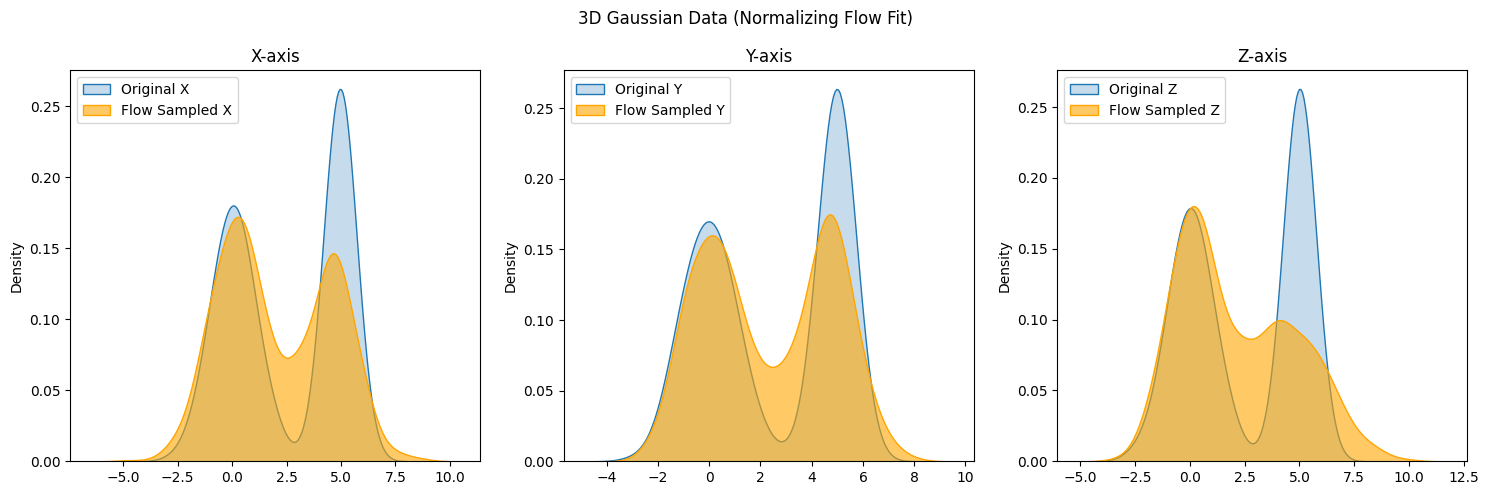

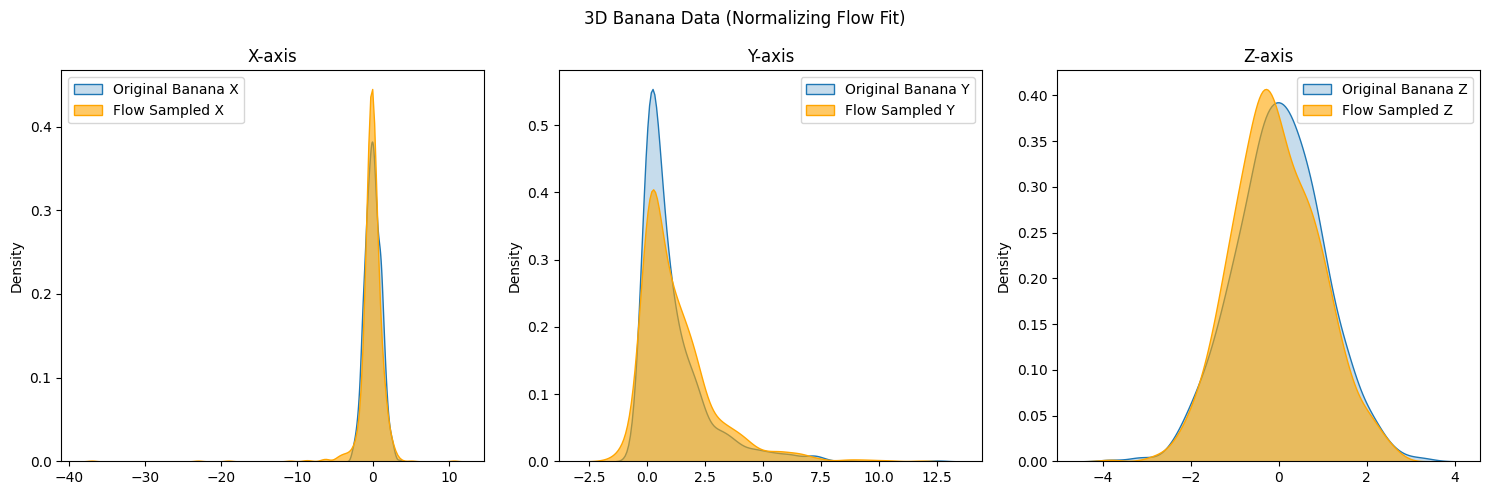

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import entropy

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Generate 3D Gaussian Data
gaussian1 = np.random.normal(loc=0, scale=1.0, size=(1000, 3))  # First cluster
gaussian2 = np.random.normal(loc=5, scale=0.5, size=(1000, 3))  # Second cluster
X = np.vstack([gaussian1, gaussian2])  # Shape: (2000, 3)
X = torch.tensor(X, dtype=torch.float32)

# Generate 3D Non-Gaussian (Banana-shaped) Data
x = np.random.normal(0, 1, 1000)
y = x**2 + np.random.normal(0, 0.1, 1000)  # Quadratic relationship
z = np.random.normal(0, 1, 1000)  # Independent dimension
banana = np.stack([x, y, z], axis=1)  # Shape: (1000, 3)
banana = torch.tensor(banana, dtype=torch.float32)

# Define Basic RealNVP Model for 3D Data
class RealNVP(nn.Module):
    def __init__(self, dim=3, hidden_dim=64):
        super(RealNVP, self).__init__()
        # Neural networks for scale and translation (split 3D into 1 and 2 dimensions)
        self.net_s1 = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
        self.net_t1 = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
        self.net_s2 = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
        self.net_t2 = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x):
        # Split input: x_a (1 dim), x_b (2 dims)
        x_a, x_b = x[:, :1], x[:, 1:]
        # First coupling layer: transform x_a based on x_b
        s1 = self.net_s1(x_b)
        t1 = self.net_t1(x_b)
        y_a = x_a * torch.exp(s1) + t1
        # Second coupling layer: transform x_b based on y_a
        s2 = self.net_s2(y_a)
        t2 = self.net_t2(y_a)
        y_b = x_b * torch.exp(s2) + t2
        y = torch.cat([y_a, y_b], dim=1)
        # Log determinant of Jacobian
        log_det = s1.sum(dim=1) + s2.sum(dim=1)
        return y, log_det

    def inverse(self, y):
        # Split input
        y_a, y_b = y[:, :1], y[:, 1:]
        # Inverse of second coupling layer
        s2 = self.net_s2(y_a)
        t2 = self.net_t2(y_a)
        x_b = (y_b - t2) * torch.exp(-s2)
        # Inverse of first coupling layer
        s1 = self.net_s1(x_b)
        t1 = self.net_t1(x_b)
        x_a = (y_a - t1) * torch.exp(-s1)
        x = torch.cat([x_a, x_b], dim=1)
        return x

# Training Function
def train_flow(model, data, epochs=1000, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        # Forward pass
        z, log_det = model(data)
        # Negative log-likelihood loss (standard normal base distribution)
        log_pz = -0.5 * torch.sum(z**2, dim=1) - 0.5 * data.shape[1] * np.log(2 * np.pi)
        loss = -(log_pz + log_det).mean()
        # Backward pass
        loss.backward()
        optimizer.step()
        if (epoch + 1) % 200 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# Sample from Flow
def sample_flow(model, n_samples):
    # Sample from standard normal
    z = torch.randn(n_samples, 3)
    # Inverse transform to data space
    samples = model.inverse(z)
    return samples.detach().numpy()

# Train and Sample for Gaussian Data
flow_gaussian = RealNVP()
train_flow(flow_gaussian, X)
generated_gaussian = sample_flow(flow_gaussian, 2000)

# Train and Sample for Banana Data
flow_banana = RealNVP()
train_flow(flow_banana, banana)
generated_banana = sample_flow(flow_banana, 1000)

# KL Divergence Function
def compute_kl_divergence(true_data, generated_data, bins=50):
    hist_true, bin_edges = np.histogram(true_data, bins=bins, density=True)
    hist_gen, _ = np.histogram(generated_data, bins=bin_edges, density=True)
    hist_true += 1e-8  # Avoid division by zero
    hist_gen += 1e-8
    hist_true /= np.sum(hist_true)  # Normalize
    hist_gen /= np.sum(hist_gen)
    return entropy(hist_true, hist_gen)

# Compute KL Divergence
# Gaussian Data
kl_x = compute_kl_divergence(X[:, 0].numpy(), generated_gaussian[:, 0])
kl_y = compute_kl_divergence(X[:, 1].numpy(), generated_gaussian[:, 1])
kl_z = compute_kl_divergence(X[:, 2].numpy(), generated_gaussian[:, 2])
print("=== 3D Gaussian Data (Normalizing Flow) ===")
print(f"KL Divergence (X-axis): {kl_x:.4f}")
print(f"KL Divergence (Y-axis): {kl_y:.4f}")
print(f"KL Divergence (Z-axis): {kl_z:.4f}")
print(f"Average KL Divergence: {(kl_x + kl_y + kl_z) / 3:.4f}")

# Banana Data
kl_bx = compute_kl_divergence(banana[:, 0].numpy(), generated_banana[:, 0])
kl_by = compute_kl_divergence(banana[:, 1].numpy(), generated_banana[:, 1])
kl_bz = compute_kl_divergence(banana[:, 2].numpy(), generated_banana[:, 2])
print("\n=== 3D Banana Data (Normalizing Flow) ===")
print(f"KL Divergence (X-axis): {kl_bx:.4f}")
print(f"KL Divergence (Y-axis): {kl_by:.4f}")
print(f"KL Divergence (Z-axis): {kl_bz:.4f}")
print(f"Average KL Divergence: {(kl_bx + kl_by + kl_bz) / 3:.4f}")

# KDE Plots - Gaussian Data
plt.figure(figsize=(15, 5))
plt.suptitle("3D Gaussian Data (Normalizing Flow Fit)")
for i, axis in enumerate(['X', 'Y', 'Z']):
    plt.subplot(1, 3, i+1)
    sns.kdeplot(X[:, i].numpy(), label=f'Original {axis}', fill=True)
    sns.kdeplot(generated_gaussian[:, i], label=f'Flow Sampled {axis}', fill=True, alpha=0.6, color='orange')
    plt.title(f"{axis}-axis")
    plt.legend()
plt.tight_layout()
plt.show()

# KDE Plots - Banana Data
plt.figure(figsize=(15, 5))
plt.suptitle("3D Banana Data (Normalizing Flow Fit)")
for i, axis in enumerate(['X', 'Y', 'Z']):
    plt.subplot(1, 3, i+1)
    sns.kdeplot(banana[:, i].numpy(), label=f'Original Banana {axis}', fill=True)
    sns.kdeplot(generated_banana[:, i], label=f'Flow Sampled {axis}', fill=True, alpha=0.6, color='orange')
    plt.title(f"{axis}-axis")
    plt.legend()
plt.tight_layout()
plt.show()